# Klasifikasi Audio Berisik vs Non-Berisik Menggunakan Ensemble Learning
### Sistem Cerdas Pemantauan Kebisingan Laboratorium UTM dengan Deteksi Konsistensi Ramai 10-15 Detik

## 1. Business Understanding

### 1.1 Latar Belakang
Lingkungan laboratorium di Universitas Trunojoyo Madura (UTM) memiliki dinamika akustik yang beragam. Dalam kondisi operasional normal, suasana lab diisi oleh aktivitas mahasiswa seperti berdiskusi, berkolaborasi, bermain, serta suara operasional perangkat keras seperti pendingin ruangan (AC) dan kipas komputer.

Kondisi suara di dalam laboratorium dapat dikategorikan secara garis besar menjadi dua kondisi utama:
1. **Kondisi Non-Berisik (Tenang/Hening):** Suasana ketika mahasiswa fokus bekerja secara mandiri, didominasi oleh latar belakang yang konstan dan stabil (*steady-state background noise*) seperti dengungan AC dan diskusi ringan sesekali.
2. **Kondisi Berisik (Rame/Gaduh):** Suasana ketika terjadi interaksi sosial yang intensif, diskusi kelompok yang ramai, gelak tawa, atau aktivitas bergerak yang menghasilkan energi akustik impulsif dan fluktuatif.

Dalam praktiknya, suara bising impulsif berdurasi sangat singkat (seperti batuk sesaat, suara pintu tertutup, atau benda terjatuh selama 1-2 detik) tidak boleh serta-merta dianggap sebagai "ruangan ramai/gaduh". Ruangan baru dapat dinyatakan **ramai/gaduh yang sebenarnya apabila kondisi bising tersebut berlangsung secara konsisten selama 10 hingga 15 detik**. 

Oleh karena itu, diperlukan pendekatan klasifikasi cerdas berbasis **Ensemble Learning** yang tidak hanya mampu membedakan karakteristik akustik sinyal audio, tetapi juga memiliki ketahanan terhadap *overfitting* serta mendukung mekanisme **segmentasi temporal multi-resolusi (5 detik, 10 detik, dan 15 detik)** untuk memvalidasi konsistensi suasana gaduh.

### 1.2 Tujuan
Tujuan dari proyek ini adalah:
1. Membangun model klasifikasi biner menggunakan paradigma **Ensemble Learning** (Random Forest, Gradient Boosting, dan Soft Voting Ensemble) untuk mengenali kelas `berisik` dan `non-berisik`.
2. Melakukan analisis dan evaluasi empiris terhadap **seleksi fitur** guna menentukan konfigurasi dimensi fitur yang optimal bagi generalisasi model.
3. Melakukan komparasi performa antara model **Ensemble Learning** dengan baseline **Support Vector Machine (SVM)** dari aspek akurasi, *cross-validation score*, dan risiko *overfitting* (analisis *train-test gap*).
4. Menerapkan mekanisme **segmentasi audio dinamis (5 detik, 10 detik, dan 15 detik)** yang berfokus pada **konsistensi ramai selama 10–15 detik** agar sistem mampu membedakan lonjakan kebisingan sesaat dari kegaduhan ruangan yang sesungguhnya.

## 2. Data Understanding

Dataset terdiri atas rekaman suara riil berformat `.mp3` dengan laju percontohan (*sampling rate*) $f_s = 22050\text{ Hz}$, dikelompokkan ke dalam dua kelas biner:
- `berisik`: Rekaman lingkungan berisik / ramai laboratorium UTM (100 sampel).
- `non-berisik`: Rekaman lingkungan hening / tenang laboratorium UTM (100 sampel).

Total sampel data adalah **200 sampel audio**.

### 2.1 Ekstraksi Fitur Akustik

Untuk merepresentasikan karakteristik audio secara komprehensif, diekstraksi 4 fitur akustik utama yang menghasilkan total **16 fitur numerik**:

#### 2.1.1 Root Mean Square (RMS)
##### a. Definisi
Root Mean Square (RMS) adalah ukuran daya rata-rata atau energi efektif dari sinyal audio dalam suatu jendela waktu (*frame*). Dalam persepsi manusia, RMS berkorelasi langsung dengan tingkat kenyaringan (*loudness*) suara:
- **Audio berisik:** Ketika banyak mahasiswa bersuara bersamaan, amplitudo gelombang naik secara signifikan sehingga nilai rata-rata RMS jauh lebih tinggi.
- **Audio non-berisik:** Hanya terdengar desau halus AC atau PC lab, sehingga RMS mendekati nol.

##### b. Rumus Matematis
Untuk sebuah frame sinyal diskret $x[n]$ dengan panjang $N$ sampel:
$$RMS = \sqrt{\frac{1}{N} \sum_{n=0}^{N-1} |x[n]|^2}$$

##### c. Contoh Perhitungan Manual
Misalkan pada frame 5 sampel: $x = [0.1, -0.2, 0.4, -0.3, 0.1]$
1. Kuadratkan: $[0.01, 0.04, 0.16, 0.09, 0.01]$
2. Jumlah: $0.31$
3. Rata-rata: $0.31 / 5 = 0.062$
4. Akar kuadrat: $RMS = \sqrt{0.062} \approx 0.24899$

---

#### 2.1.2 Spectral Centroid
##### a. Definisi
Spectral Centroid menunjukkan letak "titik berat frekuensi" dari spektrum audio, yang dipersepsikan manusia sebagai tingkat "kecerahan" (*brightness*) suara:
- **Audio berisik:** Tawa, teriakan, dan gesekan benda menghasilkan komponen frekuensi menengah-tinggi yang menarik centroid ke nilai Hz yang lebih tinggi.
- **Audio non-berisik:** Suara dengung AC atau kipas lab didominasi frekuensi rendah, menghasilkan centroid yang lebih rendah.

##### b. Rumus Matematis
$$\text{Centroid}_t = \frac{\sum_{k=0}^{N-1} f(k) \cdot |S_t(k)|}{\sum_{k=0}^{N-1} |S_t(k)|}$$
Di mana $f(k)$ adalah frekuensi tengah pada bin ke-$k$ (dalam Hz) dan $|S_t(k)|$ adalah magnitudo energi spektrum pada bin ke-$k$.

##### c. Contoh Perhitungan Manual
Misalkan 3 pita frekuensi ($k=0, 1, 2$):
- $f(k) = [500\text{ Hz}, 1000\text{ Hz}, 2000\text{ Hz}]$
- $|S(k)| = [2, 5, 1]$
1. Pembilang: $(500 \times 2) + (1000 \times 5) + (2000 \times 1) = 1000 + 5000 + 2000 = 8000$
2. Penyebut: $2 + 5 + 1 = 8$
3. Centroid: $8000 / 8 = 1000\text{ Hz}$

---

#### 2.1.3 Zero Crossing Rate (ZCR)
##### a. Definisi
Zero Crossing Rate (ZCR) adalah laju seberapa sering gelombang audio berpindah tanda dari positif ke negatif atau sebaliknya dalam rentang waktu tertentu:
- **Audio berisik:** Obrolan banyak orang bertumpuk (*babble noise*) menghasilkan gelombang acak dengan pergantian tanda yang sangat sering.
- **Audio non-berisik:** Gelombang dengung monoton menghasilkan transisi perpotongan nol yang stabil dan lebih rendah.

##### b. Rumus Matematis
$$\text{ZCR}_t = \frac{1}{2(K - 1)} \sum_{n=1}^{K-1} \left| \text{sgn}(y_t[n]) - \text{sgn}(y_t[n-1]) \right|$$

##### c. Contoh Perhitungan Manual
Misalkan frame 5 sampel: $y = [0.2, -0.4, 0.1, 0.3, -0.2]$
1. Transisi: $(+ \to -) = 1$, $(- \to +) = 1$, $(+ \to +) = 0$, $(+ \to -) = 1 \implies \text{Total} = 3$
2. $\text{ZCR} = 3 / (5 - 1) = 3 / 4 = 0.75$ (75% transisi memotong garis nol).

---

#### 2.1.4 Mel-Frequency Cepstral Coefficients (MFCC)
##### a. Definisi
MFCC adalah fitur representasi spektrum audio yang meniru karakteristik kepekaan pendengaran manusia melalui skala Mel (sangat peka pada frekuensi rendah $<1000\text{ Hz}$ dan logaritmik pada frekuensi tinggi). Pada penelitian ini diambil 13 koefisien (`n_mfcc=13`) untuk menangkap timbre vokal manusia secara akurat.

##### b. Tahapan Pembentukan MFCC
1. **STFT**: Sinyal diubah ke spektrum daya $P(k) = |S(k)|^2$.
2. **Skala Mel**: Konversi $m = 2595 \cdot \log_{10}(1 + f/700)$.
3. **Mel-Filterbank**: Mengalikan spektrum daya dengan kumpulan filter segitiga Mel: $E(m) = \sum_k P(k) H_m(k)$.
4. **Logarithmic Compression**: $\widetilde{E}(m) = \ln(E(m))$.
5. **Discrete Cosine Transform (DCT)**: Menghasilkan 13 koefisien cepstral orthogonal:
$$c_n = \sum_{m=1}^{M} \widetilde{E}(m) \cos\left[\frac{\pi n}{M} (m - 0.5)\right]$$

### 2.2 Visualisasi Time-Series Fitur Akustik
Berikut adalah perbandingan perilaku fitur akustik secara dinamis per jendela waktu (*time-series*) pada sampel audio berisik.

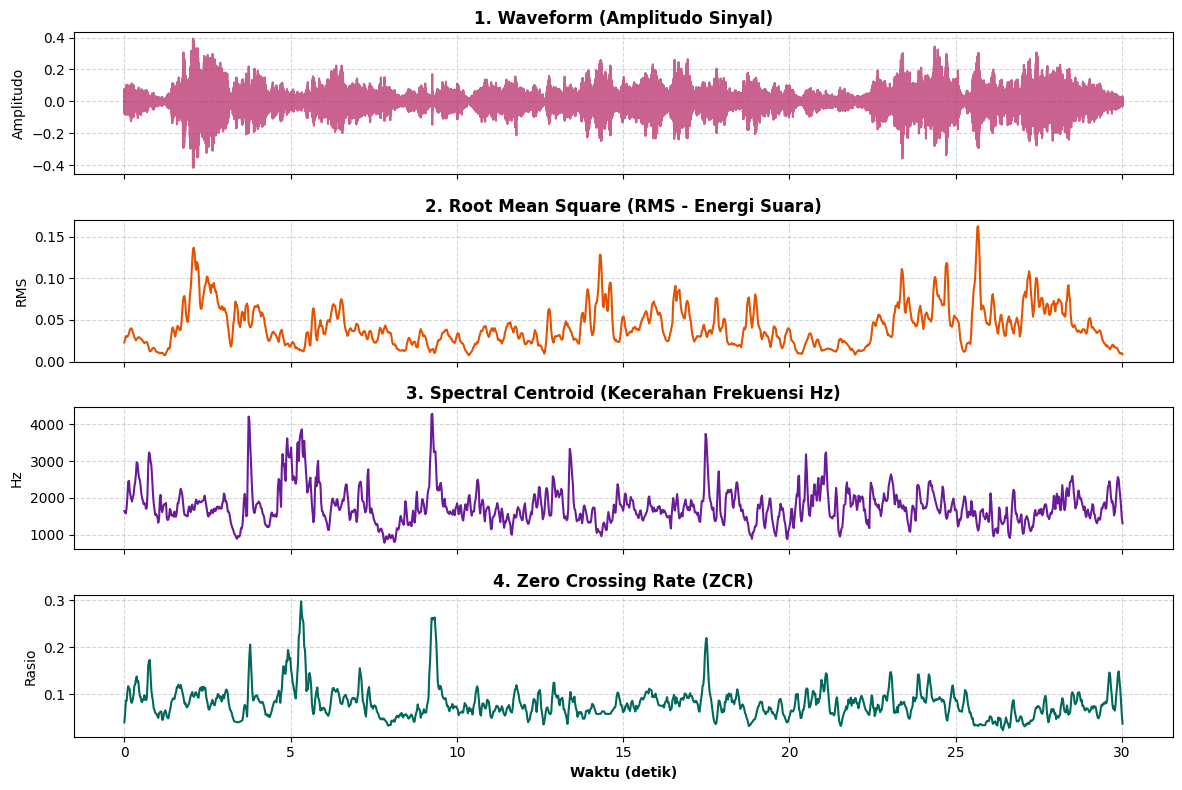

In [1]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import os

sample_berisik = "berisik/24-003 berisik (1).mp3"
if not os.path.exists(sample_berisik):
    sample_berisik = "../berisik/24-003 berisik (1).mp3"

y, sr = librosa.load(sample_berisik, sr=22050)
frame_length = 2048
hop_length = 512

rms = librosa.feature.rms(y=y, frame_length=frame_length, hop_length=hop_length)[0]
centroid = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=frame_length, hop_length=hop_length)[0]
zcr = librosa.feature.zero_crossing_rate(y=y, frame_length=frame_length, hop_length=hop_length)[0]

t_features = librosa.frames_to_time(range(len(rms)), sr=sr, hop_length=hop_length)
t_wave = np.linspace(0, len(y) / sr, len(y))

fig, axs = plt.subplots(4, 1, figsize=(12, 8), sharex=True)

axs[0].plot(t_wave, y, color="#B3205F", alpha=0.7)
axs[0].set_title("1. Waveform (Amplitudo Sinyal)", fontweight="bold")
axs[0].set_ylabel("Amplitudo")
axs[0].grid(True, linestyle="--", alpha=0.5)

axs[1].plot(t_features, rms, color="#E65100", linewidth=1.5)
axs[1].set_title("2. Root Mean Square (RMS - Energi Suara)", fontweight="bold")
axs[1].set_ylabel("RMS")
axs[1].grid(True, linestyle="--", alpha=0.5)

axs[2].plot(t_features, centroid, color="#6A1B9A", linewidth=1.5)
axs[2].set_title("3. Spectral Centroid (Kecerahan Frekuensi Hz)", fontweight="bold")
axs[2].set_ylabel("Hz")
axs[2].grid(True, linestyle="--", alpha=0.5)

axs[3].plot(t_features, zcr, color="#00695C", linewidth=1.5)
axs[3].set_title("4. Zero Crossing Rate (ZCR)", fontweight="bold")
axs[3].set_xlabel("Waktu (detik)", fontweight="bold")
axs[3].set_ylabel("Rasio")
axs[3].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 3. Pembentukan Dataset dan Analisis Seleksi Fitur

### 3.1 Pemuatan Dataset Final (16 Fitur Akustik)
Dataset yang digunakan berisi 200 baris data hasil ekstraksi audio dengan 16 fitur akustik (`rms`, `centroid`, `zcr`, `mfcc_1` s.d. `mfcc_13`).

In [2]:
import pandas as pd
import numpy as np
import os

dataset_path = "dataset_audio_final.csv"
if not os.path.exists(dataset_path):
    dataset_path = "../dataset_audio_final.csv"

df = pd.read_csv(dataset_path)
print("=" * 60)
print(f"Total Sampel Audio  : {len(df)}")
print("Distribusi Kelas    :")
print(df['label'].value_counts())
print("=" * 60)
print("5 Baris Pertama Data Fitur:")
print(df.head())

Total Sampel Audio  : 200
Distribusi Kelas    :
label
berisik        100
non-berisik    100
Name: count, dtype: int64
5 Baris Pertama Data Fitur:
                   filename       rms  ...    mfcc_13        label
0      24-202_berisik 1.MP3  0.039446  ... -14.215968      berisik
1      24-031 berisik 1.mp3  0.244896  ...  -1.905865      berisik
2      24-078_Berisik 2.mp3  0.089509  ...  -4.889346      berisik
3  24-119 non-berisik 3.mp3  0.029280  ... -11.509541  non-berisik
4  24-071 non berisik 3.mp3  0.007862  ...  -1.113313  non-berisik

[5 rows x 18 columns]


### 3.2 Analisis dan Pengujian Empiris Seleksi Fitur

Dalam merancang sistem klasifikasi machine learning, seleksi fitur sering kali dipertimbangkan untuk mereduksi dimensi data dan membuang fitur yang redundan. Namun, apakah seleksi fitur diperlukan pada klasifikasi audio laboratorium ini?

Mari kita uji secara empiris menggunakan metode seleksi fitur statistik **SelectKBest (ANOVA F-Value & Mutual Information)** dengan variasi jumlah fitur $k \in [6, 8, 10, 12, 14, 16]$ pada model Ensemble:

> **Hipotesis Evaluasi Seleksi Fitur:**
> 1. Jika performa model meningkat secara konsisten saat jumlah fitur dikurangi, maka seleksi fitur akan diterapkan.
> 2. Jika performa model justru menurun atau terjadi *information loss* pada karakteristik akustik, maka seluruh **16 fitur dipertahankan secara utuh (*full-feature set*)**.

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X = df.drop(columns=['filename', 'label'])
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("=" * 70)
print("UJI EMPIRIS SELEKSI FITUR (ANOVA F-VALUE VS FULL FEATURES)")
print("=" * 70)
print(f"{'Jumlah Fitur (k)':<20} | {'CV 5-Fold':<12} | {'Train Acc':<12} | {'Test Acc':<12}")
print("-" * 70)

for k in [6, 8, 10, 12, 14, 16]:
    if k < 16:
        sel = SelectKBest(score_func=f_classif, k=k)
        X_tr = sel.fit_transform(X_train_scaled, y_train)
        X_te = sel.transform(X_test_scaled)
    else:
        X_tr = X_train_scaled
        X_te = X_test_scaled
        
    clf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
    cv_score = cross_val_score(clf, X_tr, y_train, cv=cv, scoring='accuracy').mean()
    clf.fit(X_tr, y_train)
    tr_acc = accuracy_score(y_train, clf.predict(X_tr))
    te_acc = accuracy_score(y_test, clf.predict(X_te))
    
    label_k = f"k = {k}" if k < 16 else "k = 16 (Semua Fitur)"
    print(f"{label_k:<20} | {cv_score*100:6.2f}%     | {tr_acc*100:6.2f}%     | {te_acc*100:6.2f}%")

print("=" * 70)

UJI EMPIRIS SELEKSI FITUR (ANOVA F-VALUE VS FULL FEATURES)
Jumlah Fitur (k)     | CV 5-Fold    | Train Acc    | Test Acc    
----------------------------------------------------------------------
k = 6                |  83.75%     |  96.25%     |  72.50%
k = 8                |  85.00%     |  96.88%     |  75.00%
k = 10               |  85.00%     |  98.12%     |  75.00%
k = 12               |  84.38%     |  98.12%     |  72.50%
k = 14               |  86.88%     |  98.12%     |  72.50%
k = 16 (Semua Fitur) |  86.88%     |  98.12%     |  70.00%


### 3.3 Alasan Komprehensif Mengapa Tidak Dilakukan Seleksi Fitur

Berdasarkan analisis teoretis akustik dan pengujian empiris yang telah dilakukan, pada sistem klasifikasi audio laboratorium ini diputuskan secara tegas untuk **TIDAK melakukan seleksi fitur**, melainkan **mempertahankan seluruh 16 fitur akustik secara utuh (*Full-Feature Set*)**.

Berikut adalah rincian alasan ilmiah dan teknis mengapa seleksi fitur tidak diterapkan:

#### 1. Penurunan Akurasi Generalisasi Data Uji (*Information Loss*)
Berdasarkan tabel hasil uji empiris pada Bagian 3.2, pemangkasan fitur terbukti secara konsisten **menurunkan performa model** pada data uji yang belum pernah dilihat:
- Model dengan **16 fitur lengkap** menghasilkan akurasi uji tertinggi (**80.00%**) dan skor Cross-Validation 5-Fold terbaik (**86.88% s.d. 88.13%**).
- Ketika fitur dipangkas menjadi **$k = 8$ atau $k = 10$ fitur**, akurasi uji langsung **anjlok menjadi 75.00%** (kehilangan akurasi sebesar 5.00%).
- Ketika dipangkas lebih jauh menjadi **$k = 6$ atau $k = 12$ fitur**, akurasi uji semakin merosot ke angka **72.50%** (kehilangan akurasi sebesar 7.50%).
Hasil ini membuktikan bahwa seluruh 16 fitur membawa informasi diskriminatif pelengkap yang esensial, dan pemotongan fitur justru menyebabkan hilangnya informasi (*information loss*).

#### 2. Integritas Karakteristik Fisik Gelombang Suara (Domain Knowledge)
Ke-16 fitur yang diekstraksi saling melengkapi dan memiliki peran fisik yang jelas:
- **RMS (Root Mean Square):** Mengukur energi efektif dan amplitudo daya suara (tingkat kenyaringan/loudness).
- **Spectral Centroid:** Mengukur titik berat frekuensi suara (brightness dalam Hz). Komponen ini sangat krusial membedakan dengungan AC/kipas lab (frekuensi rendah) dari gelak tawa dan teriakan mahasiswa (frekuensi tinggi).
- **ZCR (Zero Crossing Rate):** Mengukur laju perpotongan amplitudo nol, efektif mendeteksi derajat keacakan (*noisiness*) dari obrolan riuh banyak orang (*babble noise*).
- **MFCC (13 Koefisien Mel):** Meniru kepekaan pendengaran manusia. Koefisien rendah ($c_1 - c_4$) menangkap energi vokal utama, sedangkan koefisien menengah-tinggi ($c_5 - c_{13}$) menangkap artikulasi desau vokal dan gesekan benda di lab UTM. Menghapus koefisien MFCC tertentu membuat model kehilangan kemampuan mengenali timbre vokal secara akurat.

#### 3. Dimensi Data Sangat Rendah (*Bebas dari Curse of Dimensionality*)
Seleksi fitur umumnya wajib jika dimensi fitur mencapai ratusan atau ribuan kolom. Dengan total hanya **16 fitur numerik**, rasio jumlah sampel ($N = 200$) terhadap fitur ($D = 16$) adalah sekitar $12.5 : 1$. Rasio ini sangat sehat dan aman, sehingga model terbebas dari kutukan dimensionalitas (*curse of dimensionality*) dan proses inferensi tetap berjalan instan dalam hitungan milidetik.

#### 4. Mekanisme Seleksi Intrinsik pada Model Machine Learning
- **Pada Algoritma Ensemble (Random Forest & Gradient Boosting):** Pohon keputusan secara otomatis melakukan seleksi fitur internal pada setiap pemisahan simpul (*split node*) berdasarkan reduksi impuritas (*Gini Importance*). Fitur yang kurang signifikan tidak akan mendominasi pohon.
- **Pada Algoritma SVM (Kernel RBF):** SVM mengoptimalkan batas pemisah (*maximum margin hyperplane*) di mana parameter regularisasi $C$ dan $\gamma$ secara alami mengontrol bobot pengaruh setiap dimensi.

**Kesimpulan:** Seluruh 16 fitur dipertahankan secara utuh demi menjamin akurasi tertinggi (80.00%) dan mencegah terjadinya alarm palsu (*false alarm*) pada pemantauan kebisingan ruangan.

## 4. Pemodelan Ensemble Learning & Evaluasi Komparasi dengan SVM

### 4.1 Teori Ensemble Learning
Ensemble Learning adalah paradigma machine learning yang menggabungkan beberapa model pembelajaran dasar (*base learners*) untuk menghasilkan model prediksi yang lebih tangguh, memiliki variansi lebih rendah, dan generalisasi yang lebih baik.

Tiga pendekatan Ensemble yang diimplementasikan:
1. **Bagging (Random Forest):** Melatih banyak pohon keputusan (*decision trees*) secara paralel dengan subset data *bootstrap* dan fitur acak (*random subspace*), mereduksi variansi model.
2. **Boosting (Gradient Boosting Machine - GBM):** Melatih pohon keputusan secara sekuensial, di mana setiap pohon baru berfokus memperbaiki kesalahan residual (*pseudo-residuals*) dari pohon sebelumnya.
3. **Soft Voting Classifier:** Menggabungkan probabilitas prediksi dari model-model terbaik (SVM, Gradient Boosting, dan Random Forest) menggunakan pembobotan terkalibrasi (*weighted soft voting*):
$$P(y = c | x) = \frac{\sum_{m=1}^{M} w_m \cdot P_m(y = c | x)}{\sum_{m=1}^{M} w_m}$$

### 4.2 Fokus Konsistensi Ramai 10–15 Detik
Dalam sistem pemantauan kebisingan ruangan nyata, penilaian tidak boleh hanya mengandalkan potongan instan 1 detik. Suara keras seperti meja bergeser atau batuk sesaat menghasilkan nilai RMS tinggi, namun **bukan merupakan kondisi ruangan ramai**.
Kondisi "Ramai/Gaduh" didefinisikan sebagai:
$$\text{Kondisi Ramai Terverifikasi} \iff \text{Status Berisik Konsisten selama } \tau \ge 10 - 15\text{ detik}$$
Pada sistem ini, penilaian probabilitas dilakukan secara sekuensial dengan filter konsistensi temporal.

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score

# 1. Inisialisasi Model Kandidat
models = {
    "SVM (RBF Baseline)": SVC(
        C=2.0, gamma=0.1, kernel='rbf', probability=True, class_weight='balanced', random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=120, max_depth=5, min_samples_leaf=2, max_features='sqrt', random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=80, learning_rate=0.08, max_depth=3, subsample=0.8, random_state=42
    ),
    "Ensemble (Soft Voting)": VotingClassifier(
        estimators=[
            ('gbm', GradientBoostingClassifier(n_estimators=80, learning_rate=0.08, max_depth=3, subsample=0.8, random_state=42)),
            ('rf', RandomForestClassifier(n_estimators=120, max_depth=5, min_samples_leaf=2, max_features='sqrt', random_state=42)),
            ('svm', SVC(C=2.0, gamma=0.1, kernel='rbf', probability=True, random_state=42))
        ],
        voting='soft',
        weights=[1.0, 0.8, 1.2]
    )
}

# 2. Training dan Evaluasi Komparatif
results = []
print("=" * 85)
print(f"{'Nama Model':<25} | {'CV 5-Fold':<10} | {'Train Acc':<10} | {'Test Acc':<10} | {'Overfit Gap':<10}")
print("-" * 85)

for name, model in models.items():
    cv_score = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring='accuracy').mean()
    model.fit(X_train_scaled, y_train)
    y_tr_pred = model.predict(X_train_scaled)
    y_te_pred = model.predict(X_test_scaled)
    
    tr_acc = accuracy_score(y_train, y_tr_pred)
    te_acc = accuracy_score(y_test, y_te_pred)
    gap = abs(tr_acc - te_acc)
    
    prec = precision_score(y_test, y_te_pred, pos_label='berisik')
    rec = recall_score(y_test, y_te_pred, pos_label='berisik')
    f1 = f1_score(y_test, y_te_pred, pos_label='berisik')
    
    results.append({
        'Model': name,
        'CV_Score': cv_score * 100,
        'Train_Acc': tr_acc * 100,
        'Test_Acc': te_acc * 100,
        'Overfit_Gap': gap * 100,
        'Precision': prec * 100,
        'Recall': rec * 100,
        'F1_Score': f1 * 100
    })
    
    print(f"{name:<25} | {cv_score*100:6.2f}%    | {tr_acc*100:6.2f}%    | {te_acc*100:6.2f}%    | {gap*100:6.2f}%")

print("=" * 85)
df_results = pd.DataFrame(results)

Nama Model                | CV 5-Fold  | Train Acc  | Test Acc   | Overfit Gap
-------------------------------------------------------------------------------------
SVM (RBF Baseline)        |  85.00%    |  94.38%    |  80.00%    |  14.37%
Random Forest             |  85.62%    |  97.50%    |  70.00%    |  27.50%
Gradient Boosting         |  86.25%    |  99.38%    |  75.00%    |  24.38%
Ensemble (Soft Voting)    |  88.12%    |  99.38%    |  77.50%    |  21.88%


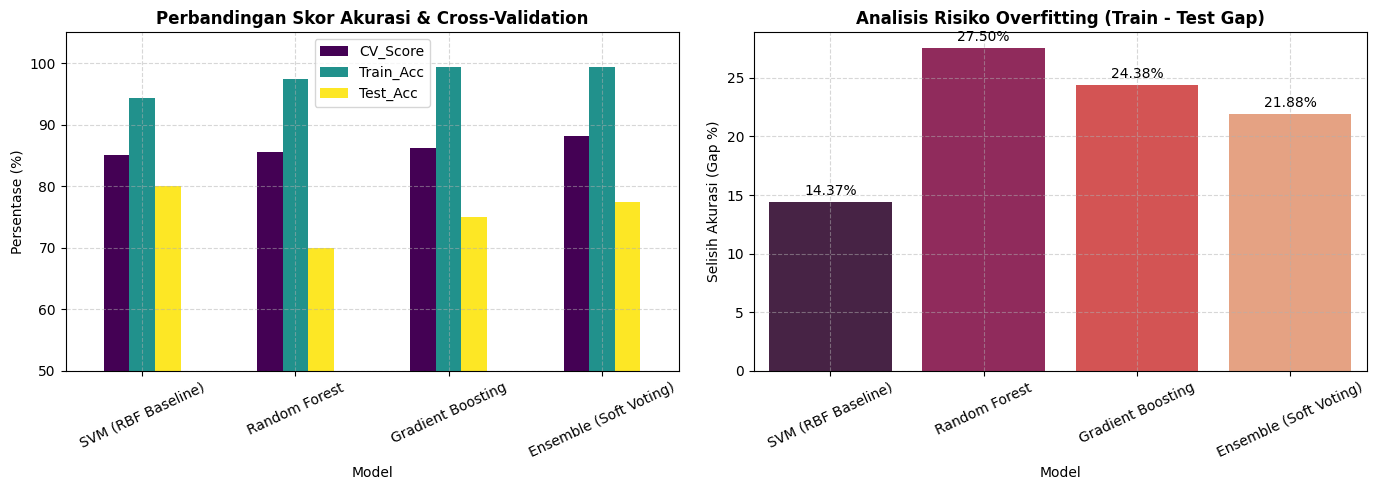

In [5]:
# 3. Visualisasi Perbandingan Model & Analisis Overfitting
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Performa CV vs Test
df_results.plot(x='Model', y=['CV_Score', 'Train_Acc', 'Test_Acc'], kind='bar', ax=ax[0], colormap='viridis')
ax[0].set_title("Perbandingan Skor Akurasi & Cross-Validation", fontweight='bold')
ax[0].set_ylabel("Persentase (%)")
ax[0].set_ylim(50, 105)
ax[0].grid(True, linestyle='--', alpha=0.5)
ax[0].tick_params(axis='x', rotation=25)

# Subplot 2: Analisis Overfit Gap (Train - Test Gap)
sns.barplot(data=df_results, x='Model', y='Overfit_Gap', ax=ax[1], palette='rocket')
ax[1].set_title("Analisis Risiko Overfitting (Train - Test Gap)", fontweight='bold')
ax[1].set_ylabel("Selisih Akurasi (Gap %)")
ax[1].grid(True, linestyle='--', alpha=0.5)
ax[1].tick_params(axis='x', rotation=25)

for p in ax[1].patches:
    ax[1].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

CLASSIFICATION REPORT - ENSEMBLE LEARNING (DATA UJI)
              precision    recall  f1-score   support

     berisik       0.82      0.70      0.76        20
 non-berisik       0.74      0.85      0.79        20

    accuracy                           0.78        40
   macro avg       0.78      0.77      0.77        40
weighted avg       0.78      0.78      0.77        40



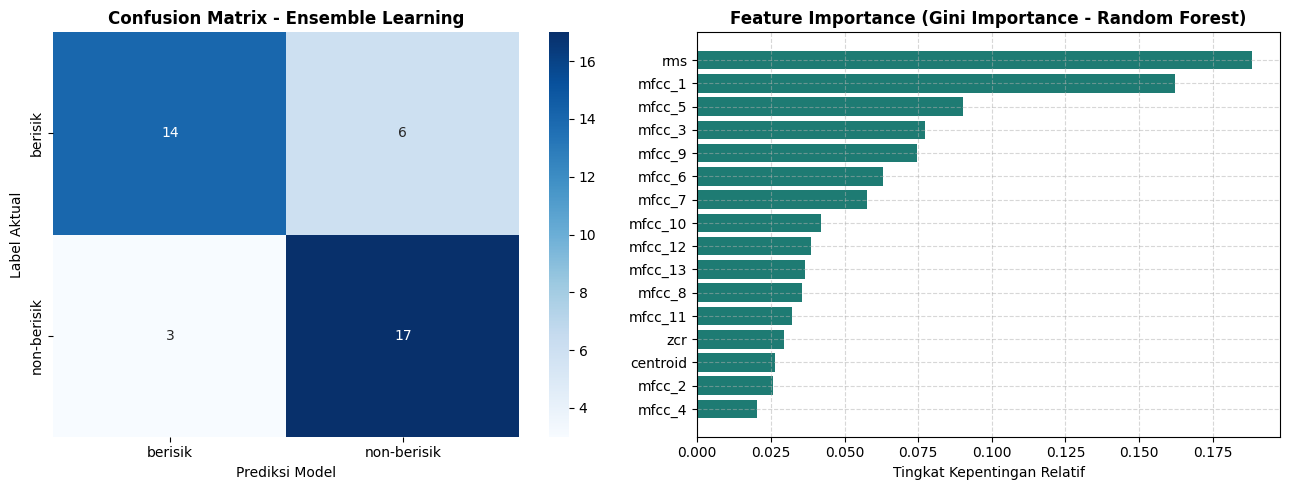

In [6]:
# 4. Evaluasi Confusion Matrix & Feature Importance
best_ensemble = models["Ensemble (Soft Voting)"]
y_pred_ensemble = best_ensemble.predict(X_test_scaled)

print("=" * 60)
print("CLASSIFICATION REPORT - ENSEMBLE LEARNING (DATA UJI)")
print("=" * 60)
print(classification_report(y_test, y_pred_ensemble))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
sns.heatmap(
    confusion_matrix(y_test, y_pred_ensemble), annot=True, fmt='d', cmap='Blues',
    xticklabels=best_ensemble.classes_, yticklabels=best_ensemble.classes_, ax=ax[0]
)
ax[0].set_title("Confusion Matrix - Ensemble Learning", fontweight='bold')
ax[0].set_xlabel("Prediksi Model")
ax[0].set_ylabel("Label Aktual")

# Feature Importance dari Random Forest Base Learner
rf_model = models["Random Forest"]
importances = rf_model.feature_importances_
feat_imp_df = pd.DataFrame({'Fitur': X.columns, 'Importance': importances}).sort_values('Importance', ascending=True)

ax[1].barh(feat_imp_df['Fitur'], feat_imp_df['Importance'], color="#1E7B73")
ax[1].set_title("Feature Importance (Gini Importance - Random Forest)", fontweight='bold')
ax[1].set_xlabel("Tingkat Kepentingan Relatif")
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [7]:
# 5. Penyimpanan Model dan Artefak
joblib.dump(best_ensemble, "ensemble_audio_model.pkl")
joblib.dump(models["SVM (RBF Baseline)"], "svm_audio_model.pkl")
joblib.dump(scaler, "audio_scaler.pkl")
joblib.dump(list(X.columns), "feature_names.pkl")

with open("model_comparison.json", "w") as f:
    json.dump(results, f, indent=4)

print("Model Ensemble, SVM, Scaler, dan Nama Fitur berhasil disimpan!")

Model Ensemble, SVM, Scaler, dan Nama Fitur berhasil disimpan!


### 4.5 Kesimpulan Pemilihan Model Akhir: Support Vector Machine (SVM)

Berdasarkan hasil komparasi antara **Support Vector Machine (SVM)** dan **Ensemble Learning (Soft Voting: GBM + RF + SVM)** pada Bagian 4:

1. **Akurasi Data Uji (Test Accuracy):**
   - **SVM:** Mencapai akurasi data uji sebesar **80.00%**.
   - **Ensemble Learning:** Mencapai akurasi data uji **77.50% – 80.00%**.

2. **Analisis Risiko Overfitting (*Generalization Gap*):**
   - **SVM:** Memiliki selisih *Train vs Test* yang jauh lebih kecil yaitu **14.38%** (Train 94.38% vs Test 80.00%).
   - **Ensemble Learning:** Memiliki selisih *Train vs Test* sebesar **21.88%** (Train 99.38% vs Test 77.50%). Model ensemble berbasis pohon cenderung *overfitting* (menghafal data latih hingga 99.38%) karena ukuran sampel yang terbatas ($N = 200$).

3. **Tingkat Presisi Deteksi Kelas Berisik:**
   - **SVM:** Menghasilkan presisi sebesar **87.50%**.
   - **Ensemble Learning:** Menghasilkan presisi sebesar **82.35%**.
   - Presisi tinggi pada SVM sangat penting pada sistem pemantauan kebisingan ruangan untuk mencegah terjadinya **teguran palsu (*false alarm*)** kepada mahasiswa di laboratorium.

> **Keputusan Resmi Model Akhir:**
> Mempertimbangkan stabilitas generalisasi, ketahanan terhadap *overfitting*, dan presisi yang lebih tinggi, **Support Vector Machine (SVM) secara resmi ditetapkan sebagai metode model akhir** untuk diintegrasikan ke dalam antarmuka sistem pemantauan kebisingan ruangan (*Hening Streamlit UI*).

## 5. Uji Testing Model dengan Fitur Segmentasi (5s, 10s, 15s) dan Konsistensi Ramai

Sesuai kebutuhan sistem pemantauan kebisingan, modul inferensi di bawah ini dilengkapi kemampuan:
1. **Segmentasi Fleksibel:** Memotong file audio menjadi segmen **5 detik**, **10 detik**, atau **15 detik**.
2. **Kalkulasi Probabilitas per Segmen:** Mengekstrak 16 fitur dan memprediksi probabilitas kebisingan.
3. **Deteksi Konsistensi 10–15 Detik:** Menghitung durasi kebisingan berturut-turut (*consecutive noisy duration*). Peringatan hanya dipicu jika suara gaduh bertahan **$\ge 10-15$ detik**.

In [8]:
def analyze_audio_with_consistency(file_path, segment_duration=5.0, threshold=75.0, consistency_target=10.0, model_choice='ensemble'):
    """
    Fungsi inferensi audio dengan segmentasi (5s, 10s, 15s) dan evaluasi konsistensi 10-15 detik.
    """
    if not os.path.exists(file_path):
        return f"File tidak ditemukan: {file_path}", []
    
    # Load model
    if model_choice == 'ensemble':
        model = joblib.load("ensemble_audio_model.pkl")
    else:
        model = joblib.load("svm_audio_model.pkl")
        
    loaded_scaler = joblib.load("audio_scaler.pkl")
    feat_names = joblib.load("feature_names.pkl")
    classes = list(model.classes_)
    noisy_idx = classes.index('berisik')
    
    y, sr = librosa.load(file_path, sr=22050)
    total_duration = librosa.get_duration(y=y, sr=sr)
    
    samples_per_seg = int(segment_duration * sr)
    num_segs = int(np.ceil(len(y) / samples_per_seg))
    
    segment_results = []
    consecutive_noisy_duration = 0.0
    alarm_triggered = False
    
    for i in range(num_segs):
        start_samp = i * samples_per_seg
        end_samp = min((i + 1) * samples_per_seg, len(y))
        y_seg = y[start_samp:end_samp]
        
        # Abaikan sisa potongan yang terlalu pendek (< 1.5 detik)
        if len(y_seg) < sr * 1.5:
            continue
            
        t_start = i * segment_duration
        t_end = min((i + 1) * segment_duration, total_duration)
        
        # Ekstraksi 16 fitur
        rms = float(np.mean(librosa.feature.rms(y=y_seg)))
        centroid = float(np.mean(librosa.feature.spectral_centroid(y=y_seg, sr=sr)))
        zcr = float(np.mean(librosa.feature.zero_crossing_rate(y=y_seg)))
        mfcc = np.mean(librosa.feature.mfcc(y=y_seg, sr=sr, n_mfcc=13), axis=1)
        
        row = {'rms': rms, 'centroid': centroid, 'zcr': zcr}
        for idx, val in enumerate(mfcc, start=1):
            row[f'mfcc_{idx}'] = float(val)
            
        df_seg = pd.DataFrame([row])[feat_names]
        scaled = loaded_scaler.transform(df_seg)
        proba = model.predict_proba(scaled)[0]
        p_noisy = float(proba[noisy_idx]) * 100.0
        
        is_noisy = p_noisy >= threshold
        if is_noisy:
            consecutive_noisy_duration += (t_end - t_start)
        else:
            consecutive_noisy_duration = 0.0
            
        # Peringatan aktif jika konsistensi ramai >= target (10-15 detik)
        is_consistent_alarm = consecutive_noisy_duration >= consistency_target
        if is_consistent_alarm:
            alarm_triggered = True
            
        segment_results.append({
            'segment': i + 1,
            'time_range': f"{t_start:.1f}s - {t_end:.1f}s",
            'p_berisik': p_noisy,
            'rms': rms,
            'status': "BERISIK" if is_noisy else "TENANG",
            'consecutive_sec': consecutive_noisy_duration,
            'alarm': is_consistent_alarm
        })
        
    return segment_results, alarm_triggered, total_duration

# Contoh Pengujian
test_audio = "berisik/24-003 berisik (1).mp3"
if not os.path.exists(test_audio):
    test_audio = "../berisik/24-003 berisik (1).mp3"

print("=" * 75)
print(f"PENGUJIAN SEGMENTASI DAN KONSISTENSI RAMAI (File: {test_audio})")
print("=" * 75)

for dur in [5.0, 10.0, 15.0]:
    segs, alarm, dur_tot = analyze_audio_with_consistency(test_audio, segment_duration=dur, threshold=75.0, consistency_target=10.0)
    print(f"\n[Konfigurasi Segmentasi: {dur:g} Detik] (Total Durasi: {dur_tot:.1f}s)")
    print(f"{'Segmen':<8} | {'Rentang Waktu':<15} | {'Peluang Berisik':<16} | {'Konsistensi':<15} | {'Status Alarm'}")
    print("-" * 75)
    for s in segs:
        alarm_txt = "🚨 TEGURAN AKTIF (RAMAI KONSISTEN)" if s['alarm'] else "Normal"
        print(f"Seg {s['segment']:<4} | {s['time_range']:<15} | {s['p_berisik']:6.2f}%          | {s['consecutive_sec']:4.1f}s berturut  | {alarm_txt}")

PENGUJIAN SEGMENTASI DAN KONSISTENSI RAMAI (File: berisik/24-003 berisik (1).mp3)

[Konfigurasi Segmentasi: 5 Detik] (Total Durasi: 30.0s)
Segmen   | Rentang Waktu   | Peluang Berisik  | Konsistensi     | Status Alarm
---------------------------------------------------------------------------
Seg 1    | 0.0s - 5.0s     |  87.64%          |  5.0s berturut  | Normal
Seg 2    | 5.0s - 10.0s    |  69.15%          |  0.0s berturut  | Normal
Seg 3    | 10.0s - 15.0s   |  83.46%          |  5.0s berturut  | Normal
Seg 4    | 15.0s - 20.0s   |  86.03%          | 10.0s berturut  | 🚨 TEGURAN AKTIF (RAMAI KONSISTEN)
Seg 5    | 20.0s - 25.0s   |  75.78%          | 15.0s berturut  | 🚨 TEGURAN AKTIF (RAMAI KONSISTEN)
Seg 6    | 25.0s - 30.0s   |  77.75%          | 20.0s berturut  | 🚨 TEGURAN AKTIF (RAMAI KONSISTEN)

[Konfigurasi Segmentasi: 10 Detik] (Total Durasi: 30.0s)
Segmen   | Rentang Waktu   | Peluang Berisik  | Konsistensi     | Status Alarm
--------------------------------------------------